# 7. Files and tables

**Programming (5AF2029)** · Université de Neuchâtel · Dr. Selena Baset

[Course home](00_index.ipynb)  ·  [Previous](06_functions_and_faults.ipynb)  ·  [Next](08_analysing_data.ipynb)

---

**Programs and data.** Most programs work with data that they do not create themselves: an export
from an accounting system, a dataset published by a statistics office, a table sent by a colleague.
Programs also often need to keep their results, so that these can be used later or by someone else.
In both cases, the data sits outside the program, in some form of storage.

**Why storage is needed.** While a program runs, it keeps its values in memory, in variables. This
memory is temporary: when the kernel restarts or the notebook is closed, the values are lost.
Storage is **persistent**: it keeps the data until it is deleted, whether or not a program is
running.

**Kinds of storage.** Data can be stored in several ways, for example:

- **text files**, such as notes or logs;
- **tabular files**, such as CSV files, where each line is a row of a table;
- **databases**, which hold large amounts of data and let many users read and update them at once;
- **cloud storage** and **document stores**, which often exchange data in the JSON format.

**What this notebook covers.** This course works with files only. The notebook shows the basic
pattern for writing and reading a text file, then how to load a table from a CSV file with pandas,
look at it, and save it again. These are the steps used to analyse data in the notebook that
follows.

## Where files live

In this course, a file is named by its path relative to the folder that contains the notebook:

- `"notes.txt"` is a file in the same folder as the notebook;
- `"data/seattle-weather.csv"` is the file `seattle-weather.csv` in the `data` folder.

## Writing and reading a text file

A program opens a file with the function `open`, in one of three modes:

| Mode | Meaning | If the file exists | If the file does not exist |
|---|---|---|---|
| `"r"` | read | its content is read | an error is raised |
| `"w"` | write | its content is erased first | it is created |
| `"a"` | append | new text is added at the end | it is created |

**Changing a file in the middle.** None of the three modes inserts text in the middle of a file. To
change a file in the middle, the program reads the whole content into memory, makes the change
there, and writes the whole content back with the mode `"w"`.

### Writing

The cell below creates the file `notes.txt` and writes two lines into it.

In [ ]:
with open("notes.txt", "w", encoding="utf-8") as file:
    file.write("Programming (5AF2029)\n")
    file.write("Lecture on files, Neuchâtel\n")

**`with open("notes.txt", "w", encoding="utf-8") as file:`** `open` opens the file and returns an
object through which the program can write into it or read from it. `as file` gives this object the
name `file`, which is used in the indented block. `with` makes Python close the file automatically
at the end of the block, which makes sure that everything written into it is saved.

`open` takes three arguments:

- **the path** of the file, here `"notes.txt"`;

- **the mode**, here `"w"`, to write into the file;

- **the encoding**, `"utf-8"`, which says how the characters are stored. UTF-8 can store any
  character, including accented letters such as the â in Neuchâtel.

**`file.write(...)`** writes into the file exactly the text it is given. It does not start a new
line by itself, so each text ends with `\n`, the new-line character.

After running the cell, `notes.txt` appears in the file browser on the left.

### Reading

With the mode `"r"`, a file can be read in one go or line by line.

The method `read` returns the whole content as one text:

In [ ]:
with open("notes.txt", "r", encoding="utf-8") as file:
    content = file.read()

print(content)

A `for` loop over the file reads it one line at a time:

In [ ]:
with open("notes.txt", "r", encoding="utf-8") as file:
    for line in file:
        print(line.strip())    # strip() removes the new-line character at the end of the line

### Appending

With the mode `"a"`, new lines are added at the end of the file, and the existing lines are kept.

In [ ]:
with open("notes.txt", "a", encoding="utf-8") as file:
    file.write("Room D61, Friday 10h15.\n")

with open("notes.txt", "r", encoding="utf-8") as file:
    print(file.read())

### A file that does not exist

Reading a file that does not exist, for example because its name is misspelled, raises a
`FileNotFoundError`. The message shows the path that Python could not find, which is the first thing
to check.

In [ ]:
with open("note.txt", "r", encoding="utf-8") as file:
    print(file.read())

---

### Exercise 1: A guest book

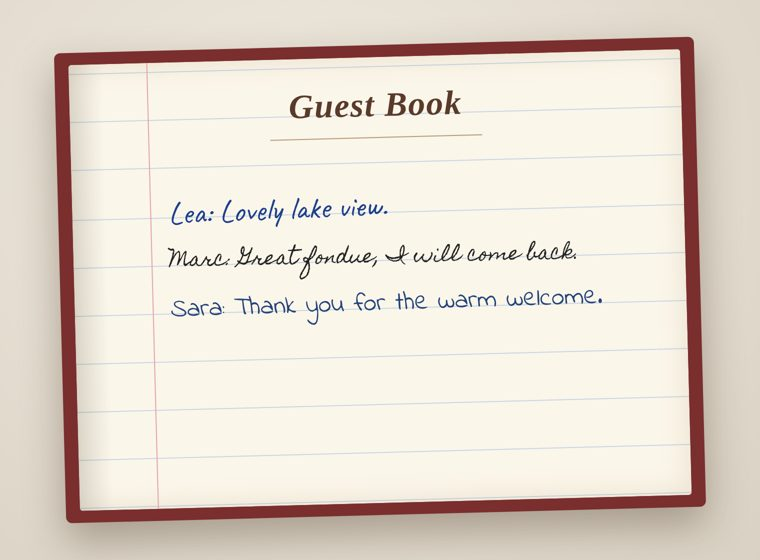

A guest book is a file in which each visitor leaves one line with their name and a short message.

**What to do:**

1. Write a function `sign(name, message)` that adds one line to the file `guestbook.txt`, in the
   form `name: message`.
2. Call it for three visitors, then print the content of the file.
3. Run the cell a second time. What do you see, and why?

In [ ]:
# Exercise 1


## Tables in CSV files

A **CSV** file, for *comma-separated values*, stores a table as text:

- each row of the table is one line of the file;
- the values of a row are separated by commas;
- the first line, the **header**, holds the names of the columns.

**The data.** The file `data/seattle-weather.csv` holds one row for each day from 2012 to 2015 in
Seattle, in the United States:

| Column | Content |
|---|---|
| `date` | the day, written year/month/day |
| `precipitation` | rain or snow over the day, in millimetres |
| `temp_max` | the highest temperature of the day, in degrees Celsius |
| `temp_min` | the lowest temperature of the day, in degrees Celsius |
| `wind` | the average wind speed, in metres per second |
| `weather` | a label for the day: sun, fog, drizzle, rain or snow |

<sub>Data: US National Oceanic and Atmospheric Administration (NOAA), public domain, as prepared for
the vega-datasets collection.</sub>

A CSV file is a text file, so it can be opened with `open`. The cell below prints its first four
lines, as they are stored.

In [ ]:
with open("data/seattle-weather.csv", "r", encoding="utf-8") as file:
    for line_number in range(4):
        # readline() reads one line; strip() removes the new-line character at its end.
        print(file.readline().strip())

### Loading a table with pandas

For a small CSV file, with a few rows and columns, reading it line by line as above is enough. For
larger tables, and for calculations on them, a library is the practical choice.

**pandas** is a Python library for working with tables of data. It is installed on Noto, and is
imported by convention under the short name `pd`.

`pd.read_csv` reads a CSV file and returns its content as a **DataFrame**, the pandas name for a
table. Each column gets a type: `temp_max` holds numbers, for example, and `weather` holds text.

In [ ]:
import pandas as pd

weather = pd.read_csv("data/seattle-weather.csv")

weather.head()

`head` shows the first five rows. The column on the left, starting at 0, is the **index**: pandas
numbers the rows itself.

`shape` gives the number of rows and of columns, and `columns` the names of the columns.

In [ ]:
print(weather.shape)
print(weather.columns)

### Selecting a column

A column is selected with its name in square brackets. It has methods for common calculations:
`mean`, `min`, `max`, `sum`, and others.

In [ ]:
print(weather["temp_max"].mean())
print(weather["temp_max"].max())

### Selecting rows

Rows are selected with a **condition** on a column. Only the rows where the condition is true are
kept.

In [ ]:
hot = weather[weather["temp_max"] > 30]

print(len(hot), "days above 30 degrees")
hot.head()

Two conditions are combined with `&`, for *and*. Each condition is then written between
parentheses.

In [ ]:
weather[(weather["temp_max"] > 30) & (weather["wind"] > 4)]

### Sorting, and adding a column

`sort_values` sorts the rows by a column. With `ascending=False`, the largest values come first.

In [ ]:
weather.sort_values("precipitation", ascending=False).head(3)

A new column is created by assigning to a new name. The calculation is done for every row at
once.

In [ ]:
weather["temp_range"] = weather["temp_max"] - weather["temp_min"]

weather.head()

### Saving a table

`to_csv` writes a DataFrame into a CSV file. With `index=False`, the row numbers are not written.

In [ ]:
hot.to_csv("hot_days.csv", index=False)

---

### Exercise 2: Weather in Seattle

Use the DataFrame `weather`.

**What to do:**

1. Compute the average lowest temperature.
2. Count the days with more than 20 millimetres of precipitation.
3. Show the five coldest days, sorted by their lowest temperature.
4. Save the days with snow, that is, with the label `snow`, into a file `snow_days.csv`, and load
   it again to check how many rows it has.

> **Hint:** 51 days have more than 20 millimetres of precipitation, and 23 days are labelled
> `snow`.

In [ ]:
# Exercise 2


---

### Before you move on

- [ ] Explain why a program needs persistent storage, and name a few kinds
- [ ] Write the relative path of a file inside a folder
- [ ] Write, read and append to a text file with `with open(...)`, and choose the right mode
- [ ] Load a CSV file with pandas, and look at it with `head`, `shape` and `columns`
- [ ] Select a column, select rows with a condition, sort, and add a calculated column
- [ ] Save a DataFrame to a CSV file

**Next:** [Analysing data](08_analysing_data.ipynb)